# Workshop 3 · Part A · Steps 1–2 — EDA, cleaning and harmonization

Goal: profile the five yearly World Happiness files, document every data-quality problem, and justify each cleaning decision that produces the **unified analytical schema**. All transformation logic lives in `etl/harmonize.py` so this notebook, the CLI (`etl/build_dataset.py`) and the tests share one code path.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from etl.harmonize import *
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160, "display.max_columns", 30)

In [2]:
raw = load_raw(ROOT / 'data' / 'raw')
for y, df in raw.items():
    print(y, df.shape)

2015 (158, 12)
2016 (157, 13)
2017 (155, 12)
2018 (156, 9)
2019 (156, 9)


## 1. Schema differences between years
The same concept has up to three different names, two files add columns the others lack, and only 2015–2016 carry `Region`.

In [3]:
cols = {y: list(df.columns) for y, df in raw.items()}
rows = []
for y, df in raw.items():
    for raw_col, uni in column_mapping(df).items():
        rows.append({"year": y, "raw_column": raw_col, "unified": uni or "(dropped)"})
mapping = pd.DataFrame(rows)
mapping.pivot_table(index="unified", columns="year", values="raw_column", aggfunc="first").fillna("—")

year,2015,2016,2017,2018,2019
unified,,,,,
(dropped),Happiness Rank,Happiness Rank,Happiness.Rank,Overall rank,Overall rank
corruption,Trust (Government Corruption),Trust (Government Corruption),Trust..Government.Corruption.,Perceptions of corruption,Perceptions of corruption
country,Country,Country,Country,Country or region,Country or region
family,Family,Family,Family,Social support,Social support
freedom,Freedom,Freedom,Freedom,Freedom to make life choices,Freedom to make life choices
gdp,Economy (GDP per Capita),Economy (GDP per Capita),Economy..GDP.per.Capita.,GDP per capita,GDP per capita
generosity,Generosity,Generosity,Generosity,Generosity,Generosity
happiness_score,Happiness Score,Happiness Score,Happiness.Score,Score,Score
health,Health (Life Expectancy),Health (Life Expectancy),Health..Life.Expectancy.,Healthy life expectancy,Healthy life expectancy


**Observations**
- Column names: `Economy (GDP per Capita)` / `Economy..GDP.per.Capita.` / `GDP per capita` (also `Family` vs `Social support`, `Health (Life Expectancy)` vs `Healthy life expectancy`, `Trust (Government Corruption)` vs `Perceptions of corruption`, `Country` vs `Country or region`).
- Column order differs (2017 swaps Generosity and Trust).
- `Region` only in 2015/2016; `Standard Error`, confidence intervals, whiskers and `Dystopia Residual` only in some years; 2018/2019 have no `Dystopia Residual`.
- Column count: 2015=12, 2016=13, 2017=12, 2018=9, 2019=9.

## 2. Missing values, duplicates, data types

In [4]:
qr = quality_report(raw, build_unified(raw))
pd.DataFrame({y: {"rows": v["rows"], "n_columns": len(v["columns"]),
                  "missing_cells": sum(v["missing_cells"].values()),
                  "exact_duplicates": v["exact_duplicates"]} for y, v in qr["per_year"].items()}).T

,rows,n_columns,missing_cells,exact_duplicates
2015,158,12,0,0
2016,157,13,0,0
2017,155,12,0,0
2018,156,9,1,0
2019,156,9,0,0


In [5]:
for y, v in qr["per_year"].items():
    if v["missing_cells"]: print(y, "missing:", v["missing_cells"])
print()
print(raw[2018][raw[2018].isna().any(axis=1)].T)

2018 missing: {'Perceptions of corruption': 1}

                                                19
Overall rank                                    20
Country or region             United Arab Emirates
Score                                        6.774
GDP per capita                               2.096
Social support                               0.776
Healthy life expectancy                       0.67
Freedom to make life choices                 0.284
Generosity                                   0.186
Perceptions of corruption                      NaN


In [6]:
# dtypes per year (after harmonizing names) - are they consistent?
pd.DataFrame({y: pd.Series({c: str(t) for c, t in df.dtypes.items()}) for y, df in raw.items()}).fillna("—")

,2015,2016,2017,2018,2019
Country,str,str,str,—,—
Country or region,—,—,—,str,str
Dystopia Residual,float64,float64,—,—,—
Dystopia.Residual,—,—,float64,—,—
Economy (GDP per Capita),float64,float64,—,—,—
Economy..GDP.per.Capita.,—,—,float64,—,—
Family,float64,float64,float64,—,—
Freedom,float64,float64,float64,—,—
Freedom to make life choices,—,—,—,float64,float64
GDP per capita,—,—,—,float64,float64


**Observations**
- Only one missing value in 5 files: `Perceptions of corruption` for the **United Arab Emirates in 2018**.
- No exact duplicate rows in any file.
- Types are consistent (floats for indicators, int rank, string country) but the *names* are not. The `Country` column is the only identifier; check that it is stable across years:

In [7]:
names = {y: set(harmonize_one(df, y)["country"]) for y, df in raw.items()}
allc = set().union(*names.values())
rename_effect = {k: v for k, v in COUNTRY_RENAMES.items()}
print("Country names that differ between files and are standardized:")
display(pd.Series(rename_effect, name="standardized to"))
# After standardization: how many years does each country appear in?
uni = build_unified(raw)
uni.groupby("country").size().value_counts().sort_index().rename("countries").to_frame().rename_axis("years present")

Country names that differ between files and are standardized:


Hong Kong S.A.R., China               Hong Kong
Taiwan Province of China                 Taiwan
Macedonia                       North Macedonia
North Cyprus                    Northern Cyprus
Somaliland Region             Somaliland region
Trinidad & Tobago           Trinidad and Tobago
Name: standardized to, dtype: str

,countries
years present,
1,4
2,3
3,2
4,9
5,146


In [8]:
print("Countries not present in all 5 years:")
presence = uni.pivot_table(index="country", columns="year", values=TARGET, aggfunc="count").fillna(0).astype(int)
presence[presence.sum(axis=1) < 5]

Countries not present in all 5 years:


year,2015,2016,2017,2018,2019
country,,,,,
Angola,1,1,1,1,0
Belize,0,1,1,1,0
Central African Republic,1,0,1,1,1
Comoros,1,1,0,0,1
Djibouti,1,0,0,0,0
Gambia,0,0,0,0,1
Laos,1,1,0,1,1
Lesotho,1,0,1,1,1
Mozambique,1,0,1,1,1


Different country sets per year are real (the survey adds/drops countries), **not** a data error, so those records are kept. Without the name standardization, e.g. *Hong Kong*, *Taiwan*, *North Macedonia* and *Trinidad and Tobago* would look like different countries in different years.

## 3. Potential outliers (IQR rule, reported not removed)

,happiness_score,gdp,family,health,freedom,generosity,corruption
IQR outliers,0,0,10,0,0,17,68


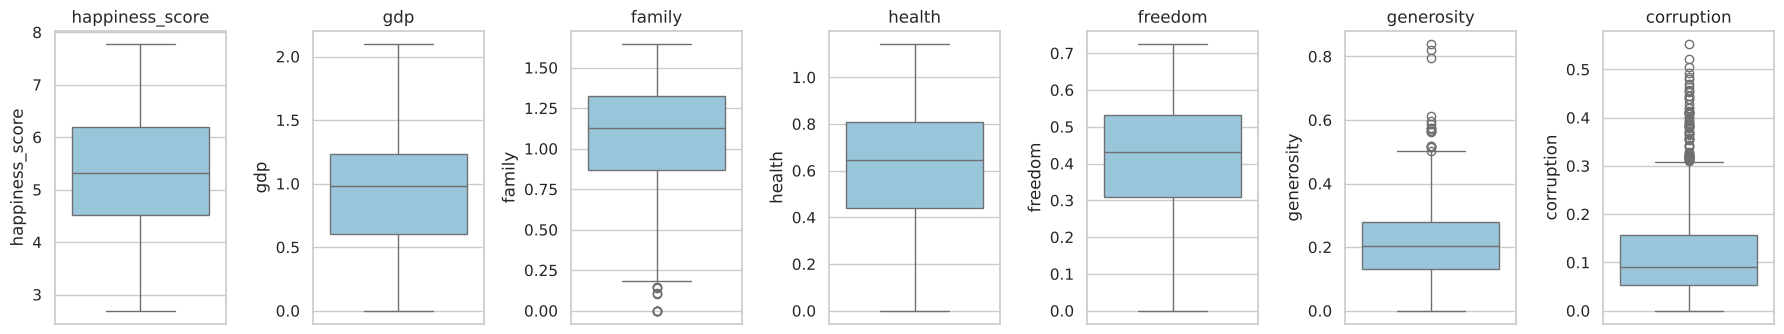

In [9]:
flags = outlier_flags(uni)
display(flags.sum().rename("IQR outliers").to_frame().T)
fig, axes = plt.subplots(1, 7, figsize=(18, 3.5))
for ax, c in zip(axes, [TARGET, *FEATURES]):
    sns.boxplot(y=uni[c], ax=ax, color="#8ecae6"); ax.set_title(c)
plt.tight_layout()

In [10]:
print("Zero values (probably 'no data' placeholders or a true floor) per feature:")
print((uni[FEATURES] == 0).sum())
uni[(uni[FEATURES] == 0).any(axis=1)][["country", "year", TARGET, *FEATURES]]

Zero values (probably 'no data' placeholders or a true floor) per feature:
gdp           5
family        5
health        5
freedom       5
generosity    5
corruption    6
dtype: int64


,country,year,happiness_score,gdp,family,health,freedom,generosity,corruption
25,Central African Republic,2015,3.678,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890
32,Congo (Kinshasa),2015,4.517,0.000000,1.001200,0.098060,0.226050,0.248340,0.076250
51,Greece,2015,4.857,1.154060,0.929330,0.882130,0.076990,0.000000,0.013970
60,Indonesia,2015,5.399,0.828270,1.087080,0.637930,0.466110,0.515350,0.000000
62,Iraq,2015,4.677,0.985490,0.818890,0.602370,0.000000,0.179220,0.137880
122,Sierra Leone,2015,4.507,0.330240,0.955710,0.000000,0.408400,0.214880,0.087860
175,Bosnia and Herzegovina,2016,5.163,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000
208,Greece,2016,5.033,1.248860,0.754730,0.800290,0.058220,0.000000,0.041270
278,Sierra Leone,2016,4.635,0.364850,0.628000,0.000000,0.306850,0.238970,0.081960
282,Somalia,2016,5.440,0.000000,0.336130,0.114660,0.567780,0.272250,0.311800


In [11]:
print("Highest GDP values:")
uni.nlargest(5, "gdp")[["country", "year", "gdp", TARGET]]

Highest GDP values:


,country,year,gdp,happiness_score
616,United Arab Emirates,2018,2.096000,6.774
428,Qatar,2017,1.870766,6.375
271,Qatar,2016,1.824270,6.375
395,Luxembourg,2017,1.741944,6.863
238,Luxembourg,2016,1.697520,6.871


**Observations / decision:** outliers concentrate in `corruption` (68, a right-skewed variable where a few countries such as Singapore/Rwanda are genuinely very high) and `generosity`. 30 rows have an exact `0` in **one** factor (e.g. Central African Republic `family`, Greece `generosity`, Somalia `gdp`, Sierra Leone `health`): these sit at the floor of the scale and look like genuine values or low-end placeholders, and are not fixable without inventing data. **They are kept**: they are published observations, a simple linear model is not very sensitive to them, and dropping them would bias the stream we replay. The UAE 2018 `gdp = 2.096` is the maximum of the whole dataset and well above the same country's other years (1.43–1.63); it is flagged here but left as published.

## 4. Cleaning decisions (and why)
| # | Problem | Decision | Justification |
|---|---------|----------|---------------|
| 1 | Inconsistent column names | Map through a normalized alias table to `country, region, year, happiness_score, gdp, family, health, freedom, generosity, corruption` | Name normalization (lowercase, alphanumerics only) makes `Economy (GDP per Capita)` and `Economy..GDP.per.Capita.` the same key; any unknown new column raises an error instead of being silently dropped |
| 2 | `Family` (2015–17) vs `Social support` (2018–19), `Trust` vs `Perceptions of corruption` | Treated as the same indicator under one name | Same Gallup construct with a renamed label; keeps a consistent 6-factor schema (caveat: definitions drifted slightly between report editions) |
| 3 | Columns not in all years / target-derived: rank, standard error, confidence interval, whiskers, dystopia residual | **Dropped** | Rank is a function of the score; dystopia residual completes `score = Σ factors + residual`; SE/CI/whiskers describe the target's uncertainty. Using them would be target leakage and they wouldn't exist at inference time |
| 4 | `Region` only in 2015/2016 | Build a country→region lookup from those years; **Gambia** (the only country missing from them) is assigned manually; keep in `dim_country` | Region is not part of the streaming event contract, so it is not a model feature, but it is useful for analytics |
| 5 | Country spelling differs across years | Standardize 6 names (see table above) | Country is the business key and the Kafka event key; inconsistent keys would split one country into several |
| 6 | Missing `corruption` (UAE, 2018) | Impute with the **same country's mean of the other years** and flag in `corruption_imputed` | Perceived corruption is slow-moving, so a country's own history is a better estimate than a global mean; only 1 of 782 rows (0.13%), and the flag keeps it auditable. Dropping the row would lose a valid target observation |
| 7 | Duplicates | Dedup on `(country, year)` | There are none, but the key is enforced so re-runs are idempotent |
| 8 | Data types | `year` int, indicators float64, text `string`, flag bool | Matches the event contract |
| 9 | Outliers | Kept, flagged | Real observations (see §3) |

## 5. Unified dataset + schema proposal

In [12]:
uni = build_unified(raw)
print(uni.shape); display(uni.dtypes.rename('dtype').to_frame())
assert not uni.duplicated(["country", "year"]).any()
assert uni[[TARGET, *FEATURES]].notna().all().all()
uni.head()

(782, 11)


,dtype
country,string
region,string
year,int64
happiness_score,float64
gdp,float64
family,float64
health,float64
freedom,float64
generosity,float64
corruption,float64


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption,corruption_imputed
0,Afghanistan,Southern Asia,2015,3.575,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719,False
1,Albania,Central and Eastern Europe,2015,4.959,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413,False
2,Algeria,Middle East and Northern Africa,2015,5.605,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,False
3,Angola,Sub-Saharan Africa,2015,4.033,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122,False
4,Argentina,Latin America and Caribbean,2015,6.574,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484,False


In [13]:
display(uni.groupby("year").size().rename("rows").to_frame().T)
display(uni[uni.corruption_imputed])

year,2015,2016,2017,2018,2019
rows,158,157,155,156,156


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption,corruption_imputed
616,United Arab Emirates,Middle East and Northern Africa,2018,6.774,2.096,0.776,0.67,0.284,0.186,0.311982,True


In [14]:
out = ROOT / "data" / "processed"; out.mkdir(parents=True, exist_ok=True)
uni.to_csv(out / "happiness_unified.csv", index=False)
(out / "quality_report.json").write_text(json.dumps(qr, indent=2))
print("saved", out / "happiness_unified.csv")

saved /home/claude/project/data/processed/happiness_unified.csv


### Unified schema proposal
| column | type | description |
|---|---|---|
| country | string | standardized country name (business key with `year`; Kafka event key) |
| region | string | geographic region (analytics only) |
| year | int | survey year, 2015–2019 |
| happiness_score | float | **target** (`actual_happiness_score` in events) |
| gdp | float | GDP per capita contribution |
| family | float | family / social support |
| health | float | healthy life expectancy |
| freedom | float | freedom to make life choices |
| generosity | float | generosity |
| corruption | float | perceptions of corruption / trust in government |
| corruption_imputed | bool | audit flag for the imputed UAE-2018 value |

## 6. Relationships between variables (Step 3 · exploration)

In [15]:
display(uni[[TARGET, *FEATURES]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769
gdp,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096
family,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644
health,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838
corruption,782.0,0.126,0.106,0.000,0.054,0.091,0.156,0.552


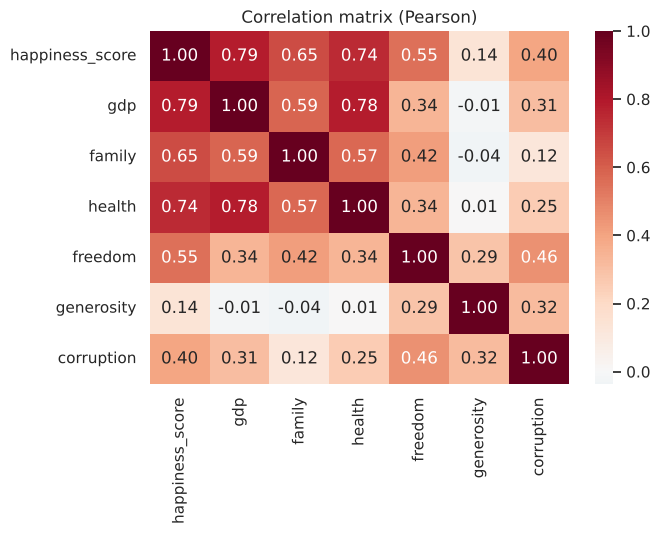

In [16]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(uni[[TARGET, *FEATURES]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation matrix (Pearson)"); plt.tight_layout()

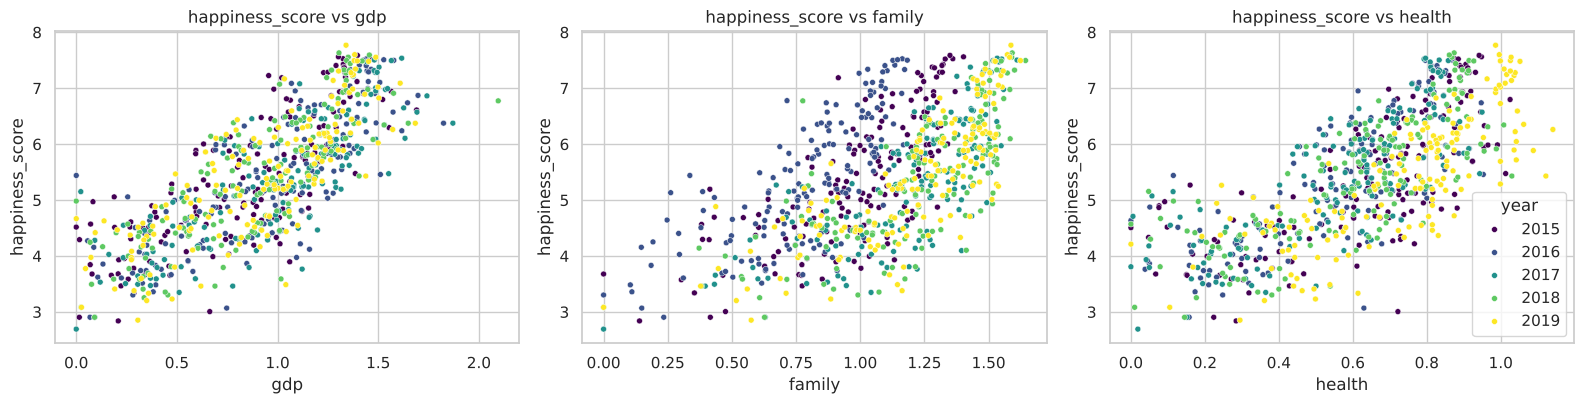

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ["gdp", "family", "health"]):
    sns.scatterplot(data=uni, x=c, y=TARGET, hue="year", palette="viridis", s=18, ax=ax, legend=(c == "health"))
    ax.set_title(f"{TARGET} vs {c}")
plt.tight_layout()

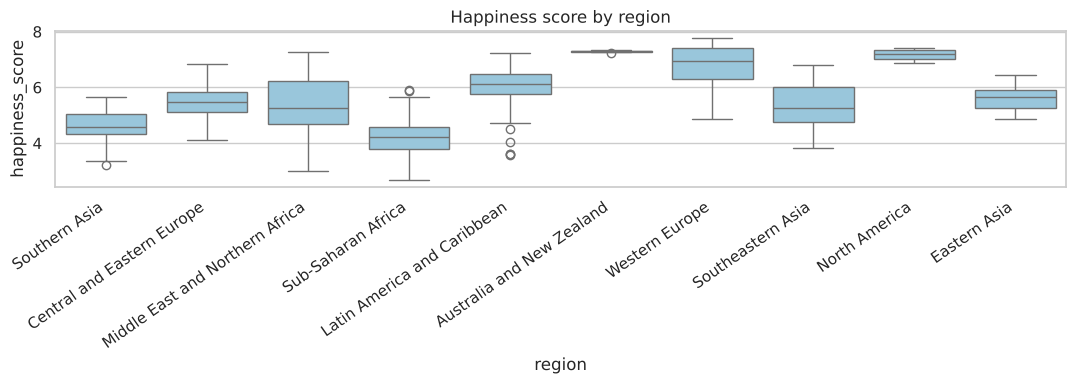

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=uni, x="region", y=TARGET, ax=ax, color="#8ecae6"); plt.xticks(rotation=35, ha="right")
ax.set_title("Happiness score by region"); plt.tight_layout()

In [19]:
uni.groupby("year")[[TARGET, *FEATURES]].mean().round(3)

,happiness_score,gdp,family,health,freedom,generosity,corruption
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.237,0.143
2016,5.382,0.954,0.794,0.558,0.371,0.243,0.138
2017,5.354,0.985,1.189,0.551,0.409,0.247,0.123
2018,5.376,0.891,1.213,0.597,0.455,0.181,0.113
2019,5.407,0.905,1.209,0.725,0.393,0.185,0.111


**Takeaways:** Correlation with the score: `gdp` 0.79, `health` 0.74, `family` 0.65, `freedom` 0.55, `corruption` 0.40, `generosity` 0.14. The factors are correlated with each other (gdp–health 0.78, gdp–family 0.59), which is fine for a plain linear model but means individual coefficients should not be over-interpreted. The scatter plots show the same pattern in every year, which supports pooling all five years.